In [1]:
import warnings
warnings.filterwarnings('ignore')
import Bio
from Bio.Data import CodonTable
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import scipy.stats as st

In [2]:
selection_val_dir = '../analysis/selection_values/'
output_dir = '../analysis/output_figures/'

In [3]:
# Import dictionary to look up amino acids for all codons
standard_table = CodonTable.unambiguous_dna_by_name["Standard"]
codon_dict = standard_table.forward_table
# Add stop codons
codon_dict['TAA'] = '*'
codon_dict['TAG'] = '*'
codon_dict['TGA'] = '*'
codons = codon_dict.keys()

In [4]:
# Read in codon level selection value dfs (with selection values calculated by summing bc counts across transfections)
wtaav2_selection_codon_trans_df = pd.read_csv(selection_val_dir + 'wtaav2_selection_values_codon_trans.csv',
                                     header=[0], index_col=[0,1,2,3,4,5], skipinitialspace=True)
wtaav2_selection_codon_trans_df.head()

virus
abs_pos aa codon aa-codon lib_type is_wt          
1       *  TAA   *-TAA    del      0      0.874808
                          sub      0      0.902054
           TAG   *-TAG    sub      0      0.545562
           TGA   *-TGA    sub      0      1.022672
        A  GCA   A-GCA    sub      0      0.884203

In [25]:
# Generate a list of all positional average selection values and positional log mean centered s' 
# (don't know why I can't do this within df...)
pos_mut_mean_list = []
log_mean_centered_s_pos_list = []
for c, codon_var in wtaav2_selection_codon_trans_df.iterrows():
#     if c[0] > 100: break
    amino_acid = c[1]
    # Exclude methionine and tryptophan codons from analysis
    if amino_acid == 'M' or amino_acid == 'W':
        continue
    s = codon_var[0]
    pos = c[0]
    wtaav2_selection_no_M_no_W = wtaav2_selection_codon_trans_df.drop(['M', 'W'], level=1)
    pos_mut_mean = wtaav2_selection_no_M_no_W.xs(pos, level=0, axis=0, drop_level=False)['virus'].mean()
    pos_mut_mean_list.append(pos_mut_mean)
    log_mean_centered_s = np.log2(s / pos_mut_mean)
    log_mean_centered_s_pos_list.append(log_mean_centered_s)

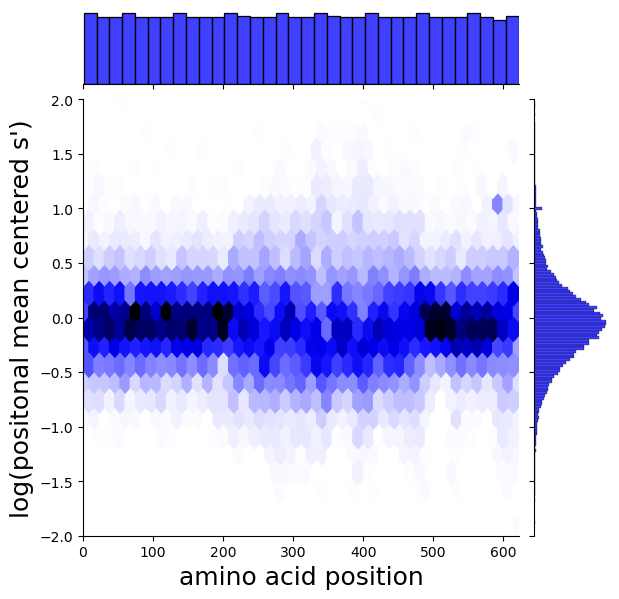

In [27]:
log_mean_centered_s_pos_no_inf = np.array(log_mean_centered_s_pos_list)
log_mean_centered_s_pos_no_inf = np.nan_to_num(log_mean_centered_s_pos_no_inf, neginf=1) 
log_mean_centered_s_pos_no_inf = np.nan_to_num(log_mean_centered_s_pos_no_inf, posinf=1)

g = sns.jointplot(x=wtaav2_selection_no_M_no_W.index.get_level_values(0),
                  y=log_mean_centered_s_pos_no_inf,
                  kind='hex', color='blue',
                  xlim=(0, 623), ylim = (-2, 2))
g.set_axis_labels('amino acid position', "log(positonal mean centered s')", size=18)
plt.savefig('../analysis/output_figures/20230918_positional_mean_cetnered_s.png')

In [28]:
# For each amino acid mutation, determine the average selection value (across synonymous codons)
# For each codon mutation, calculate the 'mean centered selection value'
# Drop selection values for all amino acids with only a single codon
wtaav2_selection_codon_trans_drop_singles_df = wtaav2_selection_codon_trans_df.drop(['M', 'W'], level=1, axis=0)
wtaav2_selection_codon_trans_drop_singles_df['aa_mut_mean'] = wtaav2_selection_codon_trans_drop_singles_df['virus'].groupby(level=[0,1]).mean()
wtaav2_selection_codon_trans_drop_singles_df['aa_mut_std'] = wtaav2_selection_codon_trans_drop_singles_df.groupby(level=[0,1])['virus'].std()
wtaav2_selection_codon_trans_drop_singles_df['log_mean_centered_s_syn'] = (wtaav2_selection_codon_trans_drop_singles_df['virus'] / wtaav2_selection_codon_trans_drop_singles_df['aa_mut_mean']).apply(np.log2)
wtaav2_selection_codon_trans_drop_singles_df['z_score'] = (wtaav2_selection_codon_trans_drop_singles_df['virus'] - wtaav2_selection_codon_trans_drop_singles_df['aa_mut_mean']) / wtaav2_selection_codon_trans_drop_singles_df['aa_mut_std']
wtaav2_selection_codon_trans_drop_singles_df.head()

virus  aa_mut_mean  aa_mut_std  \
abs_pos aa codon aa-codon lib_type is_wt                                      
1       *  TAA   *-TAA    del      0      0.874808     0.836274    0.204181   
                          sub      0      0.902054     0.836274    0.204181   
           TAG   *-TAG    sub      0      0.545562     0.836274    0.204181   
           TGA   *-TGA    sub      0      1.022672     0.836274    0.204181   
        A  GCA   A-GCA    sub      0      0.884203     0.758806    0.110974   

                                          log_mean_centered_s_syn   z_score  
abs_pos aa codon aa-codon lib_type is_wt                                     
1       *  TAA   *-TAA    del      0                     0.064991  0.188726  
                          sub      0                     0.109238  0.322166  
           TAG   *-TAG    sub      0                    -0.616232 -1.423797  
           TGA   *-TGA    sub      0                     0.290295  0.912905  
        A  GCA   A-GCA    sub      0                     0.220646  1.129970

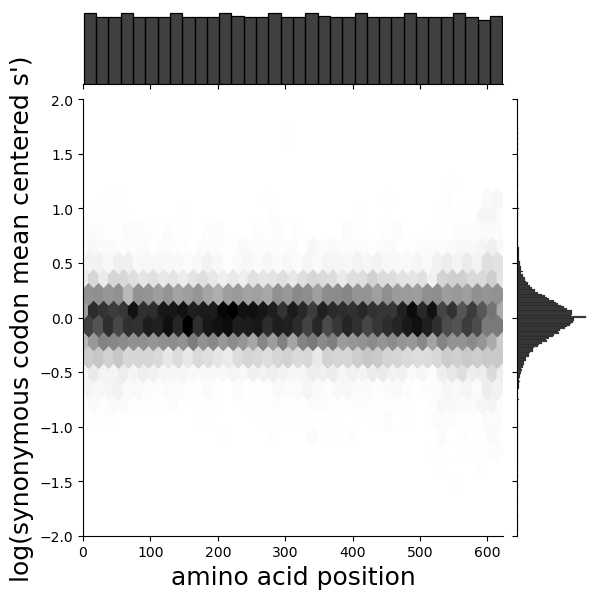

In [29]:
wtaav2_selection_codon_trans_drop_singles_df.replace([np.inf, -np.inf], np.nan, inplace=True)
# sns.set(rc={"figure.figsize":(8, 4)})
g = sns.jointplot(x=wtaav2_selection_codon_trans_drop_singles_df.index.get_level_values(0),
                  y=wtaav2_selection_codon_trans_drop_singles_df.log_mean_centered_s_syn.fillna(1),
                  kind='hex', color='black',
                  xlim=(0, 623), ylim = (-2, 2))
g.set_axis_labels('amino acid position', "log(synonymous codon mean centered s')", size=18)
plt.savefig('../analysis/output_figures/20230918_synonymous_mean_cetnered_s.png')